
# Expense Analyzer: A Python-Based Personal Expense Tracking and Data Analysis System

## 1. Problem Statement

Managing personal expenses manually makes it difficult to identify spending patterns and understand how money is distributed across different categories. This project uses Python data analysis libraries to organize expense records and generate useful spending summaries.

## 2. Objectives

- Analyze expense records using NumPy and Pandas.
- Calculate total, average, median, maximum, and minimum expenses.
- Summarize spending by category.
- Analyze monthly expenditure.
- Visualize spending patterns using Matplotlib and Seaborn.
- Establish a foundation for database integration and CSV export.

## 3. Project Scope

The notebook focuses on data loading, cleaning, statistical analysis, category-wise aggregation, monthly analysis, and visualization. SQLite integration and a web interface will be addressed in later phases.

## 4. Technologies Used

- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

## 5. Dataset Description

The initial dataset is the existing expenses.csv file in the project directory. It contains expense IDs, dates, categories, descriptions, and amounts. The records will be inspected and validated before analysis.


In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully.")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Seaborn version:", sns.__version__)


All libraries imported successfully.
NumPy version: 2.5.4
Pandas version: 3.0.6
Seaborn version: 0.13.2


In [2]:

# Locate the existing project CSV
possible_paths = [
    Path.cwd() / "expenses.csv",
    Path.cwd().parent / "expenses.csv"
]

EXPENSE_FILE = next(
    (path for path in possible_paths if path.is_file()),
    None
)

if EXPENSE_FILE is None:
    raise FileNotFoundError(
        "expenses.csv not found. Check the notebook's working directory."
    )

# Read the CSV into a Pandas DataFrame
df = pd.read_csv(EXPENSE_FILE)

print("Dataset loaded successfully!")
print("File location:", EXPENSE_FILE.resolve())
print("Dataset dimensions:", df.shape)

display(df)


Dataset loaded successfully!
File location: C:\Users\santh\OneDrive\Desktop\ExpenseAnalyzer\expenses.csv
Dataset dimensions: (2, 5)


,ID,Date,Category,Description,Amount
0,1,2026-03-20,Food,Icecream,100.0
1,2,2026-03-21,Shopping,clothes,300.0


In [3]:

print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nNumerical summary:")
display(df.describe())


Column names:
['ID', 'Date', 'Category', 'Description', 'Amount']

Data types:
ID               int64
Date               str
Category           str
Description        str
Amount         float64
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ID           2 non-null      int64  
 1   Date         2 non-null      str    
 2   Category     2 non-null      str    
 3   Description  2 non-null      str    
 4   Amount       2 non-null      float64
dtypes: float64(1), int64(1), str(3)
memory usage: 212.0 bytes

Missing values:


ID             0
Date           0
Category       0
Description    0
Amount         0
dtype: int64


Numerical summary:


,ID,Amount
count,2.000000,2.000000
mean,1.500000,200.000000
std,0.707107,141.421356
min,1.000000,100.000000
25%,1.250000,150.000000
50%,1.500000,200.000000
75%,1.750000,250.000000
max,2.000000,300.000000



## 6. Data Cleaning and Preprocessing

Data cleaning improves the reliability of the analysis by identifying missing values, invalid dates, incorrect data types, duplicate records, and invalid expense amounts.

The original CSV file is preserved. Cleaning operations are performed on a separate working DataFrame so that the source data is not modified.


In [4]:

# Preserve the loaded dataset and create a working copy
df_clean = df.copy()

# 1. Check for required columns
required_columns = [
    "ID", "Date", "Category", "Description", "Amount"
]

missing_columns = [
    column for column in required_columns
    if column not in df_clean.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Keep the required columns in a consistent order
df_clean = df_clean[required_columns].copy()

# 2. Convert columns to appropriate data types
df_clean["ID"] = pd.to_numeric(
    df_clean["ID"], errors="coerce"
)

df_clean["Date"] = pd.to_datetime(
    df_clean["Date"], errors="coerce"
)

df_clean["Amount"] = pd.to_numeric(
    df_clean["Amount"], errors="coerce"
)

# 3. Normalize text columns and identify blank values
for column in ["Category", "Description"]:
    df_clean[column] = (
        df_clean[column]
        .astype("string")
        .str.strip()
    )
    df_clean[column] = df_clean[column].replace("", pd.NA)

# 4. Remove rows with missing or invalid essential values
before_validation = len(df_clean)

df_clean = df_clean.dropna(
    subset=["ID", "Date", "Category", "Description", "Amount"]
).copy()

print("Rows removed due to missing or invalid essential values:",
      before_validation - len(df_clean))

# 5. Require positive amounts and valid positive integer IDs
valid_ids = (
    df_clean["ID"].gt(0)
    & df_clean["ID"].mod(1).eq(0)
)

valid_amounts = df_clean["Amount"].gt(0)

before_filtering = len(df_clean)

df_clean = df_clean[
    valid_ids & valid_amounts
].copy()

print("Rows removed due to invalid IDs or amounts:",
      before_filtering - len(df_clean))

# 6. Remove duplicate transaction IDs, keeping the first occurrence
before_duplicates = len(df_clean)

df_clean = df_clean.drop_duplicates(
    subset=["ID"], keep="first"
).copy()

print("Duplicate-ID rows removed:",
      before_duplicates - len(df_clean))

# 7. Convert validated IDs to integers and sort the records
df_clean["ID"] = df_clean["ID"].astype(int)

df_clean = (
    df_clean
    .sort_values(["Date", "ID"])
    .reset_index(drop=True)
)

print("\nCleaning completed.")
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))

display(df_clean)


Rows removed due to missing or invalid essential values: 0
Rows removed due to invalid IDs or amounts: 0
Duplicate-ID rows removed: 0

Cleaning completed.
Original rows: 2
Cleaned rows: 2


,ID,Date,Category,Description,Amount
0,1,2026-03-20,Food,Icecream,100.0
1,2,2026-03-21,Shopping,clothes,300.0


In [5]:

print("Final data types:")
print(df_clean.dtypes)

print("\nMissing values after cleaning:")
display(df_clean.isnull().sum())

print("\nDuplicate transaction IDs:",
      df_clean["ID"].duplicated().sum())

print("\nAll amounts are positive:",
      bool(df_clean["Amount"].gt(0).all()))

print("\nAll dates are valid:",
      bool(df_clean["Date"].notna().all()))


Final data types:
ID                      int64
Date           datetime64[us]
Category               string
Description            string
Amount                float64
dtype: object

Missing values after cleaning:


ID             0
Date           0
Category       0
Description    0
Amount         0
dtype: int64


Duplicate transaction IDs: 0

All amounts are positive: True

All dates are valid: True



## 7. Basic Statistical Analysis

Statistical analysis helps summarize expense records and understand the distribution of transaction amounts. NumPy is used for numerical calculations, while Pandas provides convenient access to and analysis of the cleaned dataset.


In [6]:

# Extract transaction amounts as a NumPy array
amounts = df_clean["Amount"].to_numpy(dtype=float)

if len(amounts) == 0:
    print("No valid expense records are available for analysis.")
else:
    # Calculate statistics using NumPy
    total_expense = np.sum(amounts)
    average_expense = np.mean(amounts)
    median_expense = np.median(amounts)
    maximum_expense = np.max(amounts)
    minimum_expense = np.min(amounts)
    standard_deviation = np.std(amounts)

    # Display results
    print("BASIC EXPENSE STATISTICS")
    print("-" * 35)
    print(f"Number of transactions : {len(df_clean)}")
    print(f"Total expenditure      : ₹{total_expense:.2f}")
    print(f"Average expense        : ₹{average_expense:.2f}")
    print(f"Median expense         : ₹{median_expense:.2f}")
    print(f"Maximum expense        : ₹{maximum_expense:.2f}")
    print(f"Minimum expense        : ₹{minimum_expense:.2f}")
    print(f"Standard deviation     : ₹{standard_deviation:.2f}")

    # Identify the largest transaction using Pandas
    largest_transaction = df_clean.loc[df_clean["Amount"].idxmax()]

    print("\nLARGEST TRANSACTION")
    print("-" * 35)
    display(largest_transaction.to_frame(name="Value"))


BASIC EXPENSE STATISTICS
-----------------------------------
Number of transactions : 2
Total expenditure      : ₹400.00
Average expense        : ₹200.00
Median expense         : ₹200.00
Maximum expense        : ₹300.00
Minimum expense        : ₹100.00
Standard deviation     : ₹100.00

LARGEST TRANSACTION
-----------------------------------


,Value
ID,2
Date,2026-03-21 00:00:00
Category,Shopping
Description,clothes
Amount,300.0


## 6. Category-wise Expenditure Analysis

This section groups expense transactions by category using Pandas `groupby()`. It calculates the total expenditure and number of transactions in each category. This analysis helps compare spending across categories and identify where money was spent in the current dataset.

In [7]:

# Phase 3, Step 6: Category-wise Expenditure Analysis

# Group transactions by category
category_summary = (
    df_clean.groupby("Category")
    .agg(
        Total_Expenditure=("Amount", "sum"),
        Number_of_Transactions=("ID", "count"),
        Average_Transaction=("Amount", "mean")
    )
    .reset_index()
    .sort_values("Total_Expenditure", ascending=False)
)

# Display the category summary
print("CATEGORY-WISE EXPENDITURE SUMMARY")
print("-" * 45)

display(
    category_summary.style.format({
        "Total_Expenditure": "₹{:,.2f}",
        "Average_Transaction": "₹{:,.2f}"
    })
)

# Identify the category with the highest expenditure
if not category_summary.empty:
    highest_category = category_summary.iloc[0]

    print("\nHIGHEST SPENDING CATEGORY")
    print(f"Category: {highest_category['Category']}")
    print(f"Total expenditure: ₹{highest_category['Total_Expenditure']:.2f}")
else:
    print("\nNo valid expense transactions are available.")


CATEGORY-WISE EXPENDITURE SUMMARY
---------------------------------------------


,Category,Total_Expenditure,Number_of_Transactions,Average_Transaction
1,Shopping,₹300.00,1,₹300.00
0,Food,₹100.00,1,₹100.00



HIGHEST SPENDING CATEGORY
Category: Shopping
Total expenditure: ₹300.00


## 7. Monthly Expenditure Analysis

This section analyzes expenditure across calendar months using Pandas. Transaction dates are converted into monthly periods, and expenses are grouped by month to calculate total expenditure, transaction count, and average transaction amount. This analysis provides a foundation for examining monthly spending patterns.

In [8]:

# Phase 3, Step 7: Monthly Expenditure Analysis

# Work with a copy to preserve df_clean
monthly_data = df_clean.copy()

# Extract the month in YYYY-MM format
monthly_data["Month"] = monthly_data["Date"].dt.to_period("M").astype(str)

# Group transactions by month
monthly_summary = (
    monthly_data.groupby("Month")
    .agg(
        Total_Expenditure=("Amount", "sum"),
        Number_of_Transactions=("ID", "count"),
        Average_Transaction=("Amount", "mean")
    )
    .reset_index()
    .sort_values("Month")
)

# Display the monthly summary
print("MONTHLY EXPENDITURE SUMMARY")
print("-" * 40)

display(
    monthly_summary.style.format({
        "Total_Expenditure": "₹{:,.2f}",
        "Average_Transaction": "₹{:,.2f}"
    })
)

# Calculate the overall monthly expenditure total
if not monthly_summary.empty:
    print(
        "\nTotal expenditure across all months: "
        f"₹{monthly_summary['Total_Expenditure'].sum():,.2f}"
    )
else:
    print("\nNo valid expense transactions are available.")


MONTHLY EXPENDITURE SUMMARY
----------------------------------------


,Month,Total_Expenditure,Number_of_Transactions,Average_Transaction
0,2026-03,₹400.00,2,₹200.00



Total expenditure across all months: ₹400.00


## 8. Data Visualization Using Matplotlib and Seaborn

Data visualization makes expense analysis easier to interpret. This section uses Seaborn and Matplotlib to create a category-wise expenditure bar chart, a pie chart showing expenditure distribution, and a monthly expenditure trend chart. The generated figures are saved in the reports directory for documentation and presentation.

In [9]:

# Phase 3, Step 8: Prepare the chart output directory

REPORT_DIR = EXPENSE_FILE.parent / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Chart output directory:", REPORT_DIR)
print("Output directory is ready:", REPORT_DIR.exists())


Chart output directory: C:\Users\santh\OneDrive\Desktop\ExpenseAnalyzer\reports
Output directory is ready: True


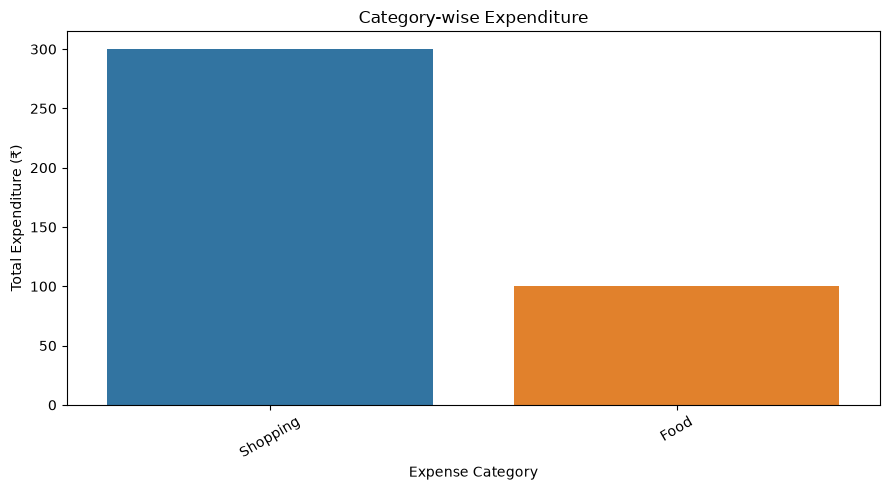

Saved: category_expenditure.png


In [10]:

# Chart 1: Category-wise Expenditure

if not category_summary.empty:
    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=category_summary,
        x="Category",
        y="Total_Expenditure",
        hue="Category",
        legend=False
    )

    plt.title("Category-wise Expenditure")
    plt.xlabel("Expense Category")
    plt.ylabel("Total Expenditure (₹)")
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.savefig(
        REPORT_DIR / "category_expenditure.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    print("Saved: category_expenditure.png")
else:
    print("No expense data available for the bar chart.")


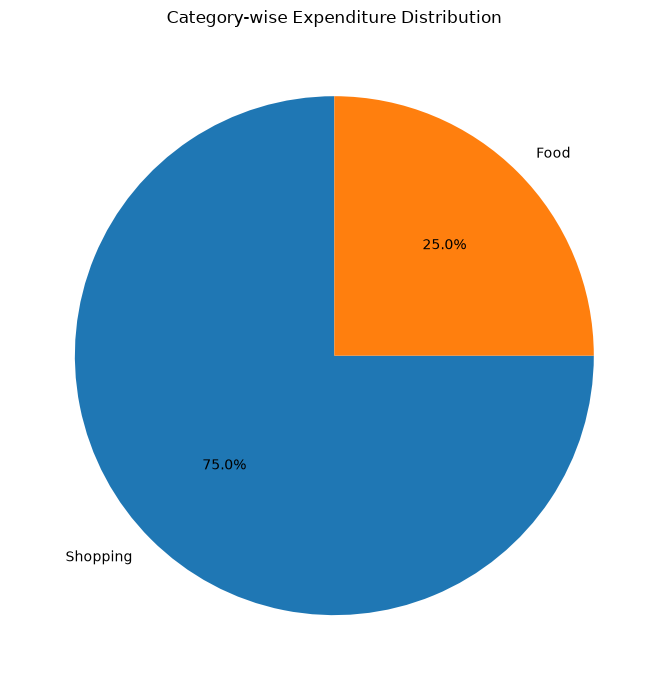

Saved: category_distribution.png


In [11]:

# Chart 2: Category-wise Expenditure Distribution

if not category_summary.empty:
    plt.figure(figsize=(7, 7))

    plt.pie(
        category_summary["Total_Expenditure"],
        labels=category_summary["Category"],
        autopct="%1.1f%%",
        startangle=90
    )

    plt.title("Category-wise Expenditure Distribution")
    plt.tight_layout()

    plt.savefig(
        REPORT_DIR / "category_distribution.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    print("Saved: category_distribution.png")
else:
    print("No expense data available for the pie chart.")


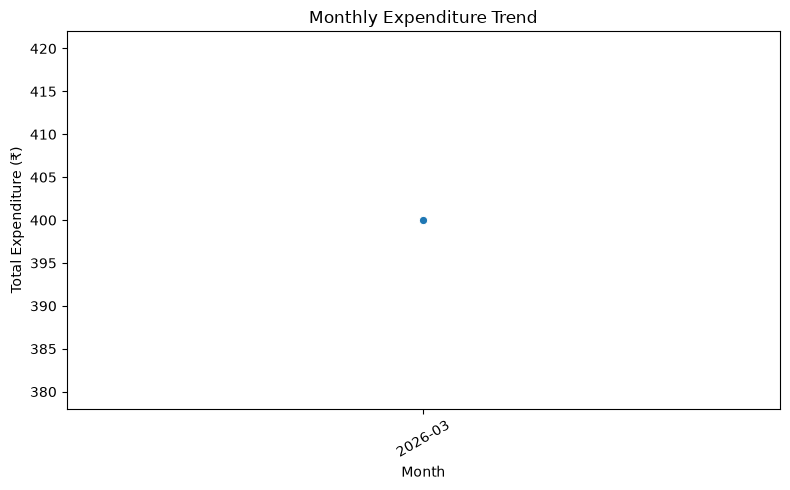

Saved: monthly_expenditure.png


In [12]:

# Chart 3: Monthly Expenditure Trend

if not monthly_summary.empty:
    plt.figure(figsize=(8, 5))

    sns.lineplot(
        data=monthly_summary,
        x="Month",
        y="Total_Expenditure",
        marker="o"
    )

    plt.title("Monthly Expenditure Trend")
    plt.xlabel("Month")
    plt.ylabel("Total Expenditure (₹)")
    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.savefig(
        REPORT_DIR / "monthly_expenditure.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    print("Saved: monthly_expenditure.png")
else:
    print("No expense data available for the monthly chart.")


## 9. Results and Interpretation

The Expense Analyzer notebook successfully loads and cleans transaction data using Pandas, calculates descriptive statistics using NumPy, and summarizes expenditure by category and month.

### Key Results

- **Number of transactions:** 2
- **Total expenditure:** ₹400
- **Average transaction amount:** ₹200
- **Highest spending category:** Shopping, ₹300
- **Food expenditure:** ₹100
- **Monthly expenditure:** ₹400 in March 2026

The category-wise bar chart and pie chart illustrate the distribution of expenditure. Shopping accounts for 75% of the recorded expenditure, while Food accounts for 25%. The monthly chart shows total expenditure for March 2026.

These findings describe only the transactions currently available in the sample dataset.

## 10. Limitations

1. The dataset contains only two transactions, so it cannot represent long-term spending habits reliably.
2. The data covers only one month, preventing meaningful month-to-month trend analysis.
3. The analysis depends on the accuracy and completeness of the recorded transactions.
4. The current notebook reads data from a CSV file; database integration and the web interface are separate implementation tasks.

## 11. Conclusion

The Expense Analyzer demonstrates how Python can be used to organize and analyze personal expense data. Pandas supports data loading, cleaning, grouping, and summarization, while NumPy provides numerical calculations. Matplotlib and Seaborn help present the results visually.

The notebook establishes the analytical foundation of the project. The remaining application development, database integration, testing, and reporting work will extend this foundation into a more complete expense management system.


## 12. Demonstration Using a 10-Record Sample Dataset

This section demonstrates the Expense Analyzer using a separate sample dataset containing 10 fictional expense transactions. The sample data is analyzed independently to preserve the original project CSV and SQLite database.

Pandas is used to load and summarize the data, while NumPy is used to calculate the total expenditure.


In [13]:
import numpy as np
import pandas as pd
# Load and analyze the separate sample dataset
from pathlib import Path

sample_candidates = [
    Path.cwd() / "data" / "sample_expenses.csv",
    Path.cwd().parent / "data" / "sample_expenses.csv"
]

SAMPLE_FILE = next(
    (path for path in sample_candidates if path.is_file()),
    None
)

if SAMPLE_FILE is None:
    raise FileNotFoundError(
        "data/sample_expenses.csv not found."
    )

sample_df = pd.read_csv(SAMPLE_FILE)

required_columns = [
    "ID", "Date", "Category", "Description", "Amount"
]

if list(sample_df.columns) != required_columns:
    raise ValueError("The sample dataset has unexpected columns.")

sample_df["Date"] = pd.to_datetime(
    sample_df["Date"], errors="coerce"
)
sample_df["Amount"] = pd.to_numeric(
    sample_df["Amount"], errors="coerce"
)

assert len(sample_df) == 10, "Expected exactly 10 records."
assert sample_df["ID"].is_unique, "Duplicate IDs detected."
assert sample_df["Date"].notna().all(), "Invalid dates detected."
assert sample_df["Amount"].gt(0).all(), "Invalid amounts detected."

sample_total = np.sum(sample_df["Amount"].to_numpy())

sample_monthly = (
    sample_df.assign(
        Month=sample_df["Date"].dt.to_period("M").astype(str)
    )
    .groupby("Month")["Amount"]
    .sum()
)

assert np.isclose(sample_total, 2779), "Total does not match."

print("SAMPLE DATASET VALIDATION")
print("-" * 35)
print("File:", SAMPLE_FILE.resolve())
print("Number of records:", len(sample_df))
print("Unique categories:", sample_df["Category"].nunique())
print("Missing values:", int(sample_df.isnull().sum().sum()))
print(f"Total expenditure: ₹{sample_total:,.2f}")

print("\nMONTHLY EXPENDITURE")
display(sample_monthly.rename("Total Expenditure").to_frame())

print("\nSAMPLE TRANSACTIONS")
display(sample_df)


SAMPLE DATASET VALIDATION
-----------------------------------
File: C:\Users\santh\OneDrive\Desktop\ExpenseAnalyzer\data\sample_expenses.csv
Number of records: 10
Unique categories: 7
Missing values: 0
Total expenditure: ₹2,779.00

MONTHLY EXPENDITURE


,Total Expenditure
Month,
2026-08,980
2026-09,1079
2026-10,720



SAMPLE TRANSACTIONS


,ID,Date,Category,Description,Amount
0,1,2026-08-02,Food,Groceries,450
1,2,2026-08-04,Transport,Bus fare,80
2,3,2026-08-09,Shopping,Notebook and pens,250
3,4,2026-08-15,Entertainment,Movie ticket,200
4,5,2026-09-03,Food,Lunch,180
5,6,2026-09-07,Education,Study materials,600
6,7,2026-09-14,Bills,Mobile recharge,299
7,8,2026-10-02,Transport,Auto fare,150
8,9,2026-10-10,Food,Dinner,350
9,10,2026-10-18,Health,First aid supplies,220
